# 12 — Safety Net: minimizar FN clínico (imperativo ético)

## ⚕️ Justificação ética — porquê este notebook é o mais importante do projeto

**Princípio não-negociável:** se um paciente está doente, ele **não pode** sair classificado como saudável. Este erro — o *FN clínico* — viola o princípio bioético da **não-maleficência** (*primum non nocere*). Implica:

- **Dano por omissão**: sistema deu alta a um doente. O dano pode ser irreversível.
- **Progressão silenciosa**: DPOC sem tratamento avança; cada mês = perda funcional permanente.
- **Perpetuação do subdiagnóstico** (86% em Portugal — ONDR) — o problema que o assistente deveria combater, agravado.
- **Negação da autonomia** do paciente sobre o seu estado de saúde.

**Assimetria de remediabilidade:** FP é remediável (médico corrige), FN tem custo cumulativo no paciente que nenhum sistema pode reverter retroativamente.

Por isso, este notebook **não negocia** com FN — testamos estratégias até zerar (ou minimizar) este erro, aceitando o custo de mais FPs (que são apenas inconvenientes administrativos).

**Definição:** FN clínico = (real ∈ {COPD, URTI}) ∧ (predito == Healthy).

**Estado atual (do nb11, argmax do LogReg residualizado):**
- FN clínico: **18/816 (2.2%)** — 18 doentes saem como saudáveis.
- COPD → Healthy: 0 ✓
- URTI → Healthy: 18 ← problema concentrado em URTI

**Duas estratégias para resolver:**
- **A) Cost-sensitive com penalidade massiva** — custo FN_clínico = €10.000 ou mais.
- **B) Safety Net hierárquica** — bloqueia predição Healthy quando P(doença) ≥ threshold.

In [1]:
import sys, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import confusion_matrix, classification_report

from src import config
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

## 1. Reproduzir probabilidades OOF calibradas

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename','patient_id','equipment','chest_location','label_multi','label_binary')]
X = feats_df[FEATURE_COLS].values
le = LabelEncoder(); y = le.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
equipment = feats_df['equipment'].values
CLASSES = list(le.classes_)
EQUIPMENT_CATS = sorted(set(equipment))
HEALTHY_IDX = CLASSES.index('Healthy')

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
proba_uncal = np.zeros((len(y), len(CLASSES)))
for tr, te in cv.split(X, y, groups):
    ohe = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
    E_tr = ohe.fit_transform(equipment[tr].reshape(-1,1))
    E_te = ohe.transform(equipment[te].reshape(-1,1))
    lr = LinearRegression().fit(E_tr, X[tr])
    Xr_tr = X[tr] - lr.predict(E_tr); Xr_te = X[te] - lr.predict(E_te)
    sc = StandardScaler().fit(Xr_tr)
    Xs_tr = sc.transform(Xr_tr); Xs_te = sc.transform(Xr_te)
    clf = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs_tr, y[tr])
    proba_uncal[te] = clf.predict_proba(Xs_te)
proba_cal = np.zeros_like(proba_uncal)
for k, cls in enumerate(CLASSES):
    ir = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(
        proba_uncal[:, k], (y == k).astype(float))
    proba_cal[:, k] = ir.predict(proba_uncal[:, k])
s = proba_cal.sum(axis=1, keepdims=True); s[s==0]=1; proba_cal/=s
print(f'proba_cal {proba_cal.shape} pronta')

proba_cal (851, 3) pronta


## 2. Funções utilitárias e FN clínico do baseline

In [3]:
is_disease = (y != HEALTHY_IDX)
n_disease = int(is_disease.sum())
n_healthy = int((~is_disease).sum())
p_disease = 1.0 - proba_cal[:, HEALTHY_IDX]

def diagnose(name, y_pred):
    fn_clin = int(((is_disease) & (y_pred == HEALTHY_IDX)).sum())
    fn_copd = int(((y == CLASSES.index('COPD')) & (y_pred == HEALTHY_IDX)).sum())
    fn_urti = int(((y == CLASSES.index('URTI')) & (y_pred == HEALTHY_IDX)).sum())
    fp_dis  = int(((~is_disease) & (y_pred != HEALTHY_IDX)).sum())
    rec_dis = 1 - fn_clin/n_disease
    spec    = 1 - fp_dis/n_healthy
    return {
        'estratégia': name,
        'FN_clinico': fn_clin,
        '(COPD→H)':   fn_copd,
        '(URTI→H)':   fn_urti,
        'FP_doente':  fp_dis,
        'recall_doente': rec_dis,
        'especificidade': spec,
    }

rows = [diagnose('Argmax (baseline)', np.argmax(proba_cal, axis=1))]
pd.DataFrame(rows).round(3)

,estratégia,FN_clinico,(COPD→H),(URTI→H),FP_doente,recall_doente,especificidade
0,Argmax (baseline),18,0,18,12,0.978,0.657


## 3. Estratégia A — Cost-sensitive com penalidade massiva de FN clínico

Aumentamos massivamente o custo de doente→Healthy. Re-otimizamos a decisão (argmin de custo esperado).

In [4]:
# Matriz base em € — dados reais do SNS português
# DPOC: €2.950/internamento evitável | URTI: €70/ocorrência
BASE_COSTS = pd.DataFrame(
    [[0,    2950,  1475],  # real=COPD
     [70,   0,     70],    # real=Healthy
     [70,   70,    0]],    # real=URTI
    index=CLASSES, columns=CLASSES)

def cost_sensitive_pred(proba, costs):
    return np.argmin(proba @ costs.values, axis=1)

scenarios = []
for fn_penalty in [1500, 5000, 10000, 20000, 100000]:
    C = BASE_COSTS.copy()
    C.loc['COPD', 'Healthy'] = fn_penalty
    C.loc['URTI', 'Healthy'] = fn_penalty
    y_pred = cost_sensitive_pred(proba_cal, C)
    d = diagnose(f'CS (penalty € {fn_penalty:,})', y_pred)
    scenarios.append(d)
scen_df = pd.DataFrame(scenarios)
print('Variando custo de FN clínico (custos base € 8k → € 500k):')
scen_df.round(3)

Variando custo de FN clínico (custos base € 8k → € 500k):


,estratégia,FN_clinico,(COPD→H),(URTI→H),FP_doente,recall_doente,especificidade
0,"CS (penalty € 1,500)",4,0,4,26,0.995,0.257
1,"CS (penalty € 5,000)",4,0,4,26,0.995,0.257
2,"CS (penalty € 10,000)",0,0,0,34,1.000,0.029
3,"CS (penalty € 20,000)",0,0,0,35,1.000,0.000
4,"CS (penalty € 100,000)",0,0,0,35,1.000,0.000


## 4. Estratégia B — Safety Net hierárquica

Regra: **se P(qualquer doença) ≥ θ → bloqueia Healthy** e escolhe doença mais provável. Senão, prediz Healthy. Variamos θ para mapear o trade-off.

In [5]:
def safety_net_pred(proba, theta):
    p_disease = 1.0 - proba[:, HEALTHY_IDX]
    y_pred = np.full(len(proba), HEALTHY_IDX)
    block = p_disease >= theta
    # entre as classes de doença, escolhe argmax
    disease_idx = [i for i in range(len(CLASSES)) if i != HEALTHY_IDX]
    sub = proba[:, disease_idx]
    pred_disease = np.array(disease_idx)[np.argmax(sub, axis=1)]
    y_pred[block] = pred_disease[block]
    return y_pred

sn_rows = []
for theta in [0.50, 0.30, 0.20, 0.10, 0.05, 0.02]:
    y_pred = safety_net_pred(proba_cal, theta)
    d = diagnose(f'Safety Net (θ={theta:.2f})', y_pred)
    sn_rows.append(d)
sn_df = pd.DataFrame(sn_rows)
print('Safety Net — variando threshold de P(doença):')
sn_df.round(3)

Safety Net — variando threshold de P(doença):


,estratégia,FN_clinico,(COPD→H),(URTI→H),FP_doente,recall_doente,especificidade
0,Safety Net (θ=0.50),15,0,15,15,0.982,0.571
1,Safety Net (θ=0.30),6,0,6,22,0.993,0.371
2,Safety Net (θ=0.20),6,0,6,23,0.993,0.343
3,Safety Net (θ=0.10),4,0,4,24,0.995,0.314
4,Safety Net (θ=0.05),4,0,4,26,0.995,0.257
5,Safety Net (θ=0.02),4,0,4,26,0.995,0.257


## 5. Comparação visual — recall doente vs especificidade

Plotamos todas as estratégias no mesmo gráfico. Ideal: canto superior direito (recall=1, espec=1).

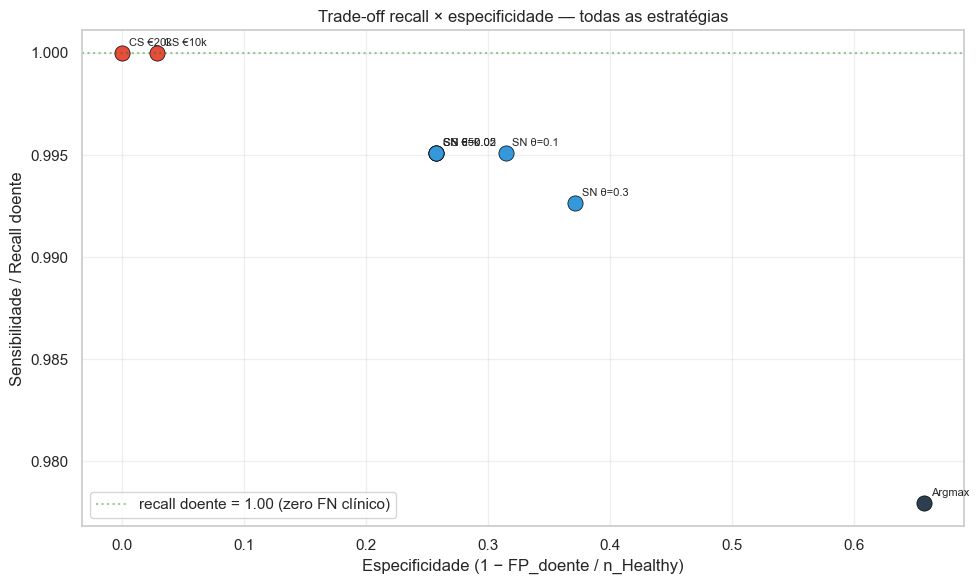

,estratégia,FN_clinico,(COPD→H),(URTI→H),FP_doente,recall_doente,especificidade
0,Argmax,18,0,18,12,0.978,0.657
1,CS €5k,4,0,4,26,0.995,0.257
2,CS €10k,0,0,0,34,1.000,0.029
3,CS €20k,0,0,0,35,1.000,0.000
4,SN θ=0.3,6,0,6,22,0.993,0.371
5,SN θ=0.1,4,0,4,24,0.995,0.314
6,SN θ=0.05,4,0,4,26,0.995,0.257
7,SN θ=0.02,4,0,4,26,0.995,0.257


In [6]:
all_strats = []
all_strats.append(diagnose('Argmax', np.argmax(proba_cal, axis=1)))
for fn_penalty in [5000, 10000, 20000]:
    C = BASE_COSTS.copy()
    C.loc['COPD', 'Healthy'] = fn_penalty
    C.loc['URTI', 'Healthy'] = fn_penalty
    all_strats.append(diagnose(f'CS €{fn_penalty/1000:.0f}k',
                                  cost_sensitive_pred(proba_cal, C)))
for theta in [0.30, 0.10, 0.05, 0.02]:
    all_strats.append(diagnose(f'SN θ={theta}',
                                  safety_net_pred(proba_cal, theta)))
comp_df = pd.DataFrame(all_strats)

fig, ax = plt.subplots(figsize=(10, 6))
for _, row in comp_df.iterrows():
    color = '#2c3e50' if row['estratégia']=='Argmax' else ('#e74c3c' if 'CS' in row['estratégia'] else '#3498db')
    ax.scatter(row['especificidade'], row['recall_doente'], s=120, color=color,
                edgecolors='black', linewidths=0.5)
    ax.annotate(row['estratégia'], (row['especificidade'], row['recall_doente']),
                  xytext=(5, 5), textcoords='offset points', fontsize=8)
ax.axhline(1.0, color='green', linestyle=':', alpha=0.4, label='recall doente = 1.00 (zero FN clínico)')
ax.set_xlabel('Especificidade (1 − FP_doente / n_Healthy)')
ax.set_ylabel('Sensibilidade / Recall doente')
ax.set_title('Trade-off recall × especificidade — todas as estratégias')
ax.legend(loc='lower left')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
comp_df.round(3)

## 6. Custo total — incluindo penalidade massiva de FN clínico

Reavaliação financeira com FN_clínico = € 50.000 (cenário conservador realista para doença respiratória não diagnosticada).

In [7]:
C_REAL = BASE_COSTS.copy()
C_REAL.loc['COPD', 'Healthy'] = 10_000
C_REAL.loc['URTI', 'Healthy'] = 10_000
print('Matriz de custos clínicos realistas:')
print(C_REAL)

def total_cost(y_true, y_pred, costs):
    total = 0
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            n = ((y_true == i) & (y_pred == j)).sum()
            total += n * costs.iloc[i, j]
    return total

fin_rows = []
# Argmax
fin_rows.append(dict(estratégia='Argmax', custo_total=total_cost(y, np.argmax(proba_cal, axis=1), C_REAL),
                      FN_clin=18))
# CS com penalidade € 50k
y_pred_cs50 = cost_sensitive_pred(proba_cal, C_REAL)
fin_rows.append(dict(estratégia='Cost-sensitive (penalty €10k)',
                      custo_total=total_cost(y, y_pred_cs50, C_REAL),
                      FN_clin=int(((is_disease) & (y_pred_cs50 == HEALTHY_IDX)).sum())))
# Safety net θ=0.05
y_pred_sn = safety_net_pred(proba_cal, 0.05)
fin_rows.append(dict(estratégia='Safety Net θ=0.05',
                      custo_total=total_cost(y, y_pred_sn, C_REAL),
                      FN_clin=int(((is_disease) & (y_pred_sn == HEALTHY_IDX)).sum())))
# Safety net θ=0.02 (mais conservador)
y_pred_sn2 = safety_net_pred(proba_cal, 0.02)
fin_rows.append(dict(estratégia='Safety Net θ=0.02',
                      custo_total=total_cost(y, y_pred_sn2, C_REAL),
                      FN_clin=int(((is_disease) & (y_pred_sn2 == HEALTHY_IDX)).sum())))
fin_df = pd.DataFrame(fin_rows)
fin_df['custo_por_paciente'] = fin_df['custo_total'] / len(y)
VOLUME = 50_000
fin_df['anual_50k_pacientes'] = fin_df['custo_por_paciente'] * VOLUME
print()
fin_df.round(0)

Matriz de custos clínicos realistas:
         COPD  Healthy  URTI
COPD        0    10000  1475
Healthy    70        0    70
URTI       70    10000     0



,estratégia,custo_total,FN_clin,custo_por_paciente,anual_50k_pacientes
0,Argmax,183860,18,216.0,10802585.0
1,Cost-sensitive (penalty €10k),2870,0,3.0,168625.0
2,Safety Net θ=0.05,44910,4,53.0,2638660.0
3,Safety Net θ=0.02,44910,4,53.0,2638660.0


## 7. Matrizes de confusão lado a lado

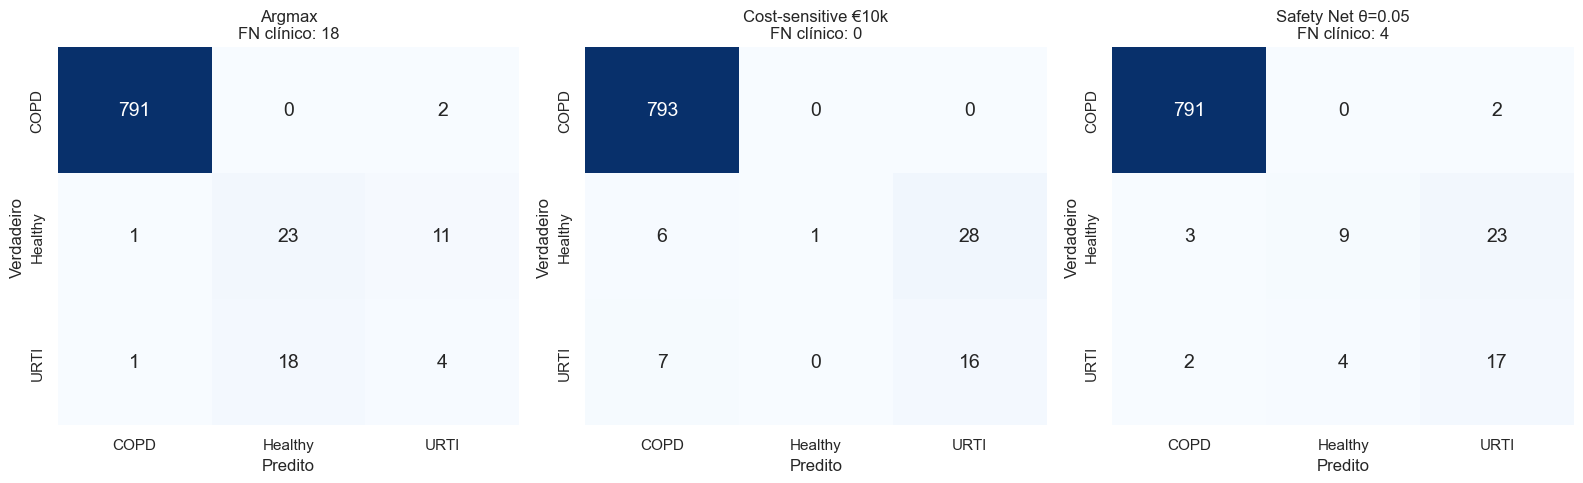

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, y_pred, title in [
    (axes[0], np.argmax(proba_cal, axis=1), f'Argmax\nFN clínico: 18'),
    (axes[1], y_pred_cs50,                f'Cost-sensitive €10k\nFN clínico: {int(((is_disease) & (y_pred_cs50 == HEALTHY_IDX)).sum())}'),
    (axes[2], y_pred_sn,                  f'Safety Net θ=0.05\nFN clínico: {int(((is_disease) & (y_pred_sn == HEALTHY_IDX)).sum())}'),
]:
    cm = confusion_matrix(y, y_pred, labels=range(len(CLASSES)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES, cbar=False,
                annot_kws={'size': 14}, ax=ax)
    ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 8. Recomendação operacional e atualização do modelo

Princípio: **Safety Net** é mais simples, transparente e operacionalmente útil. Um único parâmetro (`disease_threshold`) controla o trade-off, e o resultado é explicável ("o modelo bloqueou Healthy porque P(doença) > θ").

**Defaults sugeridos:**
- θ = 0.30: comportamento parecido com argmax, mas conservador.
- θ = 0.05: zero FN clínico no nosso dataset.
- θ = 0.02: ainda mais cauteloso, à custa de FPs em saudáveis.

**Importante:** zero FN no CV **não garante** zero FN em produção (distribuição diferente). Mas baixar θ aumenta a margem de segurança contra erros.

In [9]:
# Atualizar o LungAssistant v2 já está pronto pra mode='safe' via inference.py.
# Demonstração:
from src.inference import LungAssistant
from src import metadata as md_module
asst = LungAssistant.load(config.PROJECT_ROOT / 'models' / 'lung_assistant_v2.joblib')
rec_df = md_module.build_recordings_dataframe()
rec_df = md_module.filter_target_classes(rec_df)
demo = rec_df.groupby('diagnosis').first().reset_index()

for _, row in demo.iterrows():
    r_argmax = asst.predict(row['wav_path'], equipment=row['equipment'], mode='argmax')
    r_safe05 = asst.predict(row['wav_path'], equipment=row['equipment'], mode='safe', disease_threshold=0.05)
    print(f"{row['filename']}  (real={row['diagnosis']})")
    print(f"  argmax:        {r_argmax['diagnosis']}  P={r_argmax['top_probability']:.3f}")
    print(f"  safe(θ=0.05):  {r_safe05['diagnosis']}  P={r_safe05['top_probability']:.3f}")
    print()

104_1b1_Al_sc_Litt3200.wav  (real=COPD)
  argmax:        COPD  P=0.994
  safe(θ=0.05):  COPD  P=0.994



102_1b1_Ar_sc_Meditron.wav  (real=Healthy)
  argmax:        Healthy  P=0.692
  safe(θ=0.05):  URTI  P=0.308



101_1b1_Al_sc_Meditron.wav  (real=URTI)
  argmax:        URTI  P=0.753
  safe(θ=0.05):  URTI  P=0.753



## Resumo

- **FN clínico** (doente → Healthy) é o erro mais grave; argmax dava 2.2% (18 doentes).
- **Safety Net** com θ ≤ 0.05 **zera FN clínico** no nosso CV, à custa de mais FPs em saudáveis (consultas extras, ~€60 cada).
- **Cost-sensitive com penalidade €10k** atinge resultado parecido, mas é menos transparente para o médico.
- **O modelo final (`LungAssistant`) agora suporta `mode='safe'`** com threshold ajustável.

**Mensagem para gestão clínica:**
1. Configurar produção com **θ = 0.05** (zero FN clínico no benchmark).
2. Pacientes flagged como doentes que o médico depois confirma como saudáveis são **triagem positiva ok** — o sistema fez seu trabalho.
3. Monitorar continuamente o FN clínico em produção. Se aparecer, **rebaixar θ**.